<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-070c-qcnn.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 070c. A quantum convolutional neural network that recognises a topological phase

A quantum simulator prepares the ground state of a spin chain at some values of its couplings, and we want to know in which phase of matter this state lies. Reading out the full state would need tomography, whose cost grows exponentially with the number of qubits, and for a symmetry-protected topological (SPT) phase no local measurement can tell the phases apart. A quantum convolutional neural network (QCNN) [1] answers the question directly on the device. It is a short circuit that acts on the quantum state itself, halves the number of qubits in every layer and finally measures one qubit, whose outcome is the class. The autoencoder notebook found phase boundaries without labels. The QCNN is its supervised counterpart, trained on states whose phase is known.

**Task.**

| | |
|---|---|
| Input | ground state $\lvert\psi(h_1,h_2)\rangle$ of the cluster-Ising chain with $N=8$ qubits, prepared on the device |
| Output | one measured qubit, $p=P(1)$ is the predicted probability of the SPT phase, class SPT when $p>1/2$ |
| Training data | $M=40$ ground states at random points $(h_1,h_2)$, labelled by the exact string order parameter |
| Trained | the shared convolution, pooling and final unitaries, 57 angles in total |
| Success | accuracy of the predicted phase diagram on a grid of 528 points against the exact boundary |

All results are exact state-vector simulations, and on a device $p$ would be estimated as the fraction of shots that return 1. Sections 1 to 8 form the classroom route and run in under a minute on a laptop CPU. Section 9 is an optional check of the exact boundary by a second method and takes less than one more minute. Section 10 lists exercises for home.

## 1. Double-precision arithmetic

We work in double precision on the CPU. JAX evaluates the circuit and its gradient, NumPy and SciPy compute the exact ground states, and Matplotlib draws the figures. Every random seed is fixed.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # small calculations, never the GPU
os.environ["OPENBLAS_NUM_THREADS"] = "1"     # small matrices, avoids thread contention with JAX
import json, time
from pathlib import Path
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as sla
import jax
import jax.numpy as jnp
from jax.scipy.linalg import expm
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
TOL = 1e-10
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
NAVY, BLUE, ORANGE, GRAY, GREEN = "#002B5C", "#3E8FD0", "#D35A05", "#5A6270", "#1B7F36"
plt.rcParams.update({"font.size": 13, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
                     "legend.fontsize": 11.5, "figure.figsize": (4.8, 3.2), "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight", "pdf.fonttype": 42, "ps.fonttype": 42})
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=200)
started = time.perf_counter()
RESULTS = {}
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. From a convolutional network to a quantum circuit

A classical convolutional neural network (CNN) classifies an image in three kinds of layers. A convolution layer slides one small filter, a few weights that combine neighbouring pixels, over the whole image, so the same local feature is detected at every position and the number of weights does not depend on the image size. A pooling layer coarse-grains the resulting feature map, for instance by keeping one value out of every two neighbours, which halves the map. After several rounds of convolution and pooling the map is small, and a fully connected layer turns the few remaining numbers into class probabilities.

The QCNN keeps this structure, with three changes forced by quantum mechanics. Its input is a quantum state of $N$ qubits, a vector of $2^N$ amplitudes that we cannot read out, and every layer acts on it as a quantum operation.

1. **Convolution.** One two-qubit unitary $\hat U_\ell$ acts on all neighbouring pairs, first on the pairs $(q_0,q_1),(q_2,q_3),\dots$ and then on the shifted pairs $(q_1,q_2),\dots,(q_{N-1},q_0)$. The same unitary at every position plays the role of the shared filter weights.
2. **Pooling.** In every pair one qubit is measured, and its partner is rotated by $\hat V^{(0)}_\ell$ or $\hat V^{(1)}_\ell$ depending on the outcome. The measured qubit is not used again, so the register halves. The measurement is the only nonlinear step, the counterpart of the activation function.
3. **Fully connected layer and readout.** When two qubits remain, a general two-qubit unitary $\hat F$ acts on them, and one of them is measured. The probability $p$ of the outcome 1 is the network output.

A general two-qubit unitary has 15 real parameters and a single-qubit unitary has 3. With one shared unitary per layer, each convolution-pooling unit carries $15+6=21$ angles, and $N=2^L$ qubits need $L-1$ such units plus the final 15 angles. The number of parameters,
$$n=21(\log_2N-1)+15 , \tag{1}$$
grows only logarithmically with $N$. For $N=8$ it is $n=57$. The sketch below shows the circuit for $N=8$, with the matching CNN layer above each block.

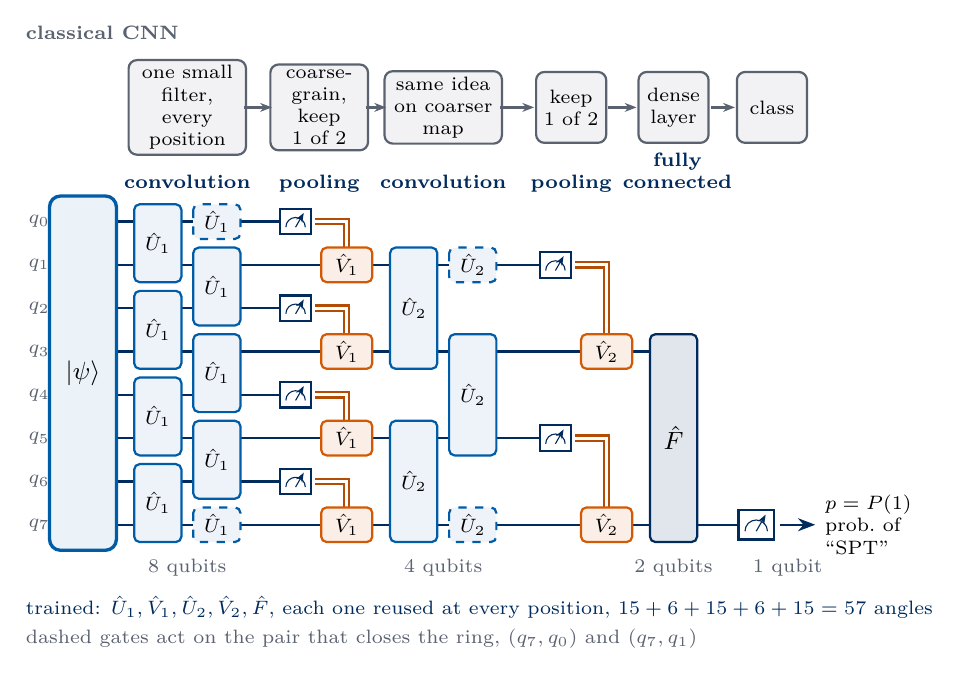

The input state enters on the left. The dashed gates close the ring, so every qubit has two neighbours. After the first pooling the even qubits are gone and the convolution acts on $q_1,q_3,q_5,q_7$, after the second pooling only $q_3$ and $q_7$ remain, and $q_7$ is measured at the end.

## 3. The cluster-Ising chain and its topological phase

We classify ground states of the cluster-Ising chain studied in Ref. [1]. On a ring of $N$ qubits, with $\hat X_i,\hat Z_i$ the Pauli operators of qubit $i$ and indices taken modulo $N$,
$$\hat{\mathcal H}=-J\sum_{i=0}^{N-1}\hat Z_{i-1}\hat X_i\hat Z_{i+1}-h_1\sum_{i=0}^{N-1}\hat X_i-h_2\sum_{i=0}^{N-1}\hat X_i\hat X_{i+1} , \tag{2}$$
with $J=1$. Each of the three terms prefers a different ground state.

* **Cluster term.** The three-qubit operators $\hat K_i=\hat Z_{i-1}\hat X_i\hat Z_{i+1}$ commute with each other and square to the identity. Their common eigenstate with all $\hat K_i=+1$ is the cluster state $\lvert C\rangle$, the ground state at $h_1=h_2=0$. It is highly entangled, and every single qubit in it is completely random, $\langle\hat X_i\rangle=\langle\hat Z_i\rangle=0$.
* **Field $h_1$.** For $h_1\gg J$ the ground state approaches the product state $\lvert+\rangle^{\otimes N}$, a paramagnet with all spins along $x$.
* **Coupling $h_2$.** For $h_2\ll -J$ neighbouring spins point in opposite $x$ directions, an antiferromagnet. For $h_2>0$ the coupling aligns them and, together with the field, produces again the paramagnet.

The Hamiltonian has two symmetries, the spin flips $\hat X_{\rm even}=\prod_{i\ {\rm even}}\hat X_i$ and $\hat X_{\rm odd}=\prod_{i\ {\rm odd}}\hat X_i$. Both commute with every term of (2), because each $\hat K_i$ contains two $\hat Z$ operators on qubits of equal parity and each flip changes the sign of both. The group generated by the two flips is called $\mathbb Z_2\times\mathbb Z_2$.

The phase around the cluster state is a symmetry-protected topological (SPT) phase. Its ground state is unique and gapped, no symmetry is broken, and all single-qubit expectation values look like those of a featureless state, so no local order parameter distinguishes it from the paramagnet. Yet the two cannot be connected by any path of gapped, symmetric Hamiltonians, and the difference is hidden in a non-local correlation. The product of the stabilisers $\hat K_1\hat K_3\cdots\hat K_{2m-1}$ collapses, because the inner $\hat Z$ factors square to the identity, to the string operator
$$\hat S=\hat Z_0\,\hat X_1\hat X_3\cdots\hat X_{2m-1}\,\hat Z_{2m} . \tag{3}$$
We take $2m=N/2$, half of the ring. The string order parameter $S=\langle\hat S\rangle$ equals 1 in the cluster state, because $\hat S$ is a product of stabilisers with eigenvalue $+1$. It vanishes in $\lvert+\rangle^{\otimes N}$, where the two end operators $\hat Z_0$ and $\hat Z_{2m}$ average to zero. In a long chain $S$ stays finite throughout the SPT phase and decays to zero outside it [2]. A long string is a hard observable to measure accurately near a transition, where its value is small and the shot noise of a $\pm1$ outcome is largest, and this is where Ref. [1] found the QCNN useful.

The next cell builds (2) and (3) as sparse matrices and computes exact ground states by diagonalisation. It checks the symmetries, the cluster state and the two limits of $S$.

In [2]:
I2 = sp.identity(2, format="csr")
X = sp.csr_matrix([[0., 1.], [1., 0.]]); Z = sp.csr_matrix([[1., 0.], [0., -1.]])

def op_on(n, ops):
    # Kronecker product with ops[q] on qubit q and the identity elsewhere; qubit 0 is the leftmost factor
    out = sp.identity(1, format="csr")
    for q in range(n):
        out = sp.kron(out, ops.get(q, I2), format="csr")
    return out

def hamiltonian_terms(n):
    # the three sums of equation (2) on a ring of n qubits
    zxz = sum(op_on(n, {(i - 1) % n: Z, i: X, (i + 1) % n: Z}) for i in range(n))
    xs = sum(op_on(n, {i: X}) for i in range(n))
    xx = sum(op_on(n, {i: X, (i + 1) % n: X}) for i in range(n))
    return zxz, xs, xx

def string_operator(n):
    # equation (3): Z_0 X_1 X_3 ... X_{n/2-1} Z_{n/2}
    ops = {0: Z, n // 2: Z}; ops.update({q: X for q in range(1, n // 2, 2)})
    return op_on(n, ops)

def ground_state(terms, h1, h2, J=1.0):
    H = -J * terms[0] - h1 * terms[1] - h2 * terms[2]
    if H.shape[0] <= 256:
        psi = np.linalg.eigh(H.toarray())[1][:, 0]
    else:
        psi = sla.eigsh(H, k=1, which="SA", tol=1e-12)[1][:, 0]
    return psi * np.sign(psi[np.argmax(np.abs(psi))])

N = 8
T8, S8 = hamiltonian_terms(N), string_operator(N)
X_even, X_odd = op_on(N, {q: X for q in range(0, N, 2)}), op_on(N, {q: X for q in range(1, N, 2)})
for t in T8:
    assert abs(t @ X_even - X_even @ t).max() < TOL and abs(t @ X_odd - X_odd @ t).max() < TOL

cluster = ground_state(T8, 0.0, 0.0)
for i in range(N):
    K = op_on(N, {(i - 1) % N: Z, i: X, (i + 1) % N: Z})
    assert abs(cluster @ (K @ cluster) - 1) < TOL                     # every stabiliser equals +1
    assert abs(cluster @ (op_on(N, {i: Z}) @ cluster)) < TOL and abs(cluster @ (op_on(N, {i: X}) @ cluster)) < TOL
plus = np.ones(2 ** N) / 2 ** (N / 2)
assert abs(cluster @ (S8 @ cluster) - 1) < TOL and abs(plus @ (S8 @ plus)) < TOL
print("S in the cluster state:", round(cluster @ (S8 @ cluster), 12), "| S in |+...+>:", round(plus @ (S8 @ plus), 12))
for h1, h2 in [(0.5, 0.0), (0.5, 1.5), (0.5, -1.5)]:
    v = ground_state(T8, h1, h2)
    print(f"h1 = {h1}, h2 = {h2:+.1f}:  S = {v @ (S8 @ v):.3f},  <X_0> = {v @ (op_on(N, {0: X}) @ v):+.3f}")

S in the cluster state: 1.0 | S in |+...+>: 0.0
h1 = 0.5, h2 = +0.0:  S = 0.917,  <X_0> = +0.291
h1 = 0.5, h2 = +1.5:  S = 0.070,  <X_0> = +0.974
h1 = 0.5, h2 = -1.5:  S = 0.164,  <X_0> = +0.017


The cluster state has $S=1$ and vanishing single-qubit expectation values, as derived above. Inside the SPT region, at $(h_1,h_2)=(0.5,0)$, the string order is still large, while in the paramagnet and the antiferromagnet it is small. The magnetisation $\langle\hat X_0\rangle$ of the SPT state lies between its values in the paramagnet and in the antiferromagnet, so this local quantity changes gradually across the diagram and does not single out the SPT phase.

## 4. Labels from the exact string order parameter

The label of a training state is a property of the point $(h_1,h_2)$, its phase. We take it from the best reference we can compute exactly, the string order parameter $S_{12}$ of the ground state of a ring with 12 sites, and call a point SPT when $S_{12}>1/2$. The longer ring gives a sharper boundary than the 8-qubit chain fed to the QCNN, and Section 9 confirms its position by an independent method. Ref. [1] located the boundary in the infinite chain by the density-matrix renormalisation group (DMRG) and found the SPT phase ending at $h_2/J=0.423$ along the line $h_1/J=0.5$.

The grid of test points has 16 values $h_1\in[0.05,1.55]$ and 33 values $h_2\in[-1.6,1.6]$. We leave out $h_1=0$, where at $h_2>1$ the two ferromagnetic states are exactly degenerate and the ground state is not unique. The cell computes the 8-qubit ground states, their string order $S_8$ and the reference $S_{12}$ on the whole grid.

528 grid points in 10.3 s; fraction labelled SPT: 0.396


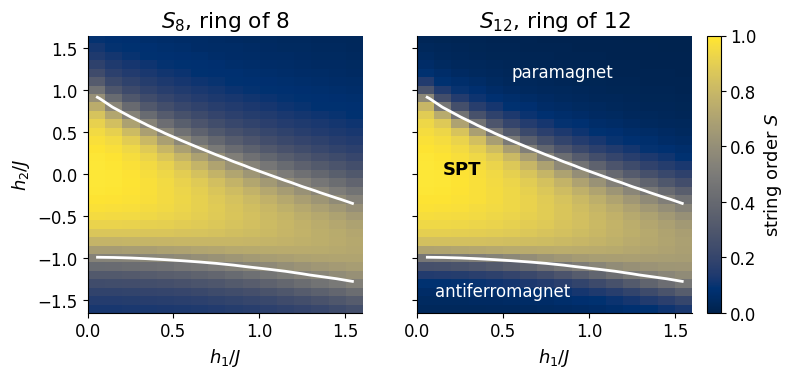

In [3]:
H1_GRID = np.round(np.arange(0.05, 1.6, 0.1), 3)
H2_GRID = np.round(np.linspace(-1.6, 1.6, 33), 3)
GRID = [(a, b) for b in H2_GRID for a in H1_GRID]            # row = h2, column = h1
T12, S12 = hamiltonian_terms(12), string_operator(12)

t0 = time.perf_counter()
G8 = np.array([ground_state(T8, a, b) for a, b in GRID])
sop8 = np.einsum("ij,ij->i", G8, (S8 @ G8.T).T).reshape(len(H2_GRID), len(H1_GRID))
sop12 = np.array([(lambda v: v @ (S12 @ v))(ground_state(T12, a, b)) for a, b in GRID]).reshape(len(H2_GRID), len(H1_GRID))
LABELS = (sop12 > 0.5).astype(float)
RESULTS["grid_points"] = len(GRID); RESULTS["spt_fraction"] = float(LABELS.mean())
print(f"{len(GRID)} grid points in {time.perf_counter() - t0:.1f} s; fraction labelled SPT: {LABELS.mean():.3f}")

EXT = [H1_GRID[0] - 0.05, H1_GRID[-1] + 0.05, H2_GRID[0] - 0.05, H2_GRID[-1] + 0.05]
fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.6), sharey=True)
for ax, data, title in zip(axs, (sop8, sop12), (r"$S_8$, ring of 8", r"$S_{12}$, ring of 12")):
    im = ax.imshow(data, origin="lower", extent=EXT, aspect="auto", cmap="cividis", vmin=0, vmax=1)
    ax.contour(H1_GRID, H2_GRID, sop12, levels=[0.5], colors="white", linewidths=2)
    ax.set_title(title); ax.set_xlabel(r"$h_1/J$")
axs[1].text(0.15, 0.0, "SPT", fontsize=13, fontweight="bold")
axs[1].text(0.55, 1.15, "paramagnet", color="white", fontsize=12); axs[1].text(0.1, -1.45, "antiferromagnet", color="white", fontsize=12)
axs[0].set_ylabel(r"$h_2/J$"); fig.colorbar(im, ax=axs, pad=0.02, label="string order $S$")
save(fig, "fig_lab070c_reference"); plt.show()

Both maps show a bright band of large string order around the cluster point, bounded above by the paramagnet and below by the antiferromagnet. The white line, $S_{12}=1/2$, is our reference boundary. It crosses $h_2=0$ near $h_1=J$, the transition of the exactly solvable line $h_2=0$ [1], and at $h_1=0.5$ it lies close to the DMRG value $0.423$. The 8-qubit string order changes more gradually across the same line, as expected for a shorter chain. The lower boundary bends downwards for larger $h_1$, so the SPT band continues to the right edge of the map.

## 5. The QCNN circuit

We now write the circuit of Section 2. A two-qubit unitary is parametrised by 15 angles $c_k$ as the exponential of the 15 two-qubit Pauli strings $\hat P_k$ other than the identity,
$$\hat U(\boldsymbol c)=\exp\Big(-i\sum_{k=1}^{15}c_k\hat P_k\Big) , \tag{4}$$
which reaches every two-qubit unitary up to a global phase. A single-qubit unitary uses the three Pauli matrices in the same way.

Pooling measures qubit $a$ and rotates its partner $b$ according to the outcome. The same result follows from the controlled unitary
$$\hat C=\lvert0\rangle\langle0\rvert_a\otimes\hat V^{(0)}_b+\lvert1\rangle\langle1\rvert_a\otimes\hat V^{(1)}_b \tag{5}$$
followed by ignoring qubit $a$, because a measurement of $a$ that is never looked at again gives the same reduced state of the other qubits as no measurement at all. This principle of deferred measurement lets us simulate the whole QCNN as one unitary on the state vector. The cell below checks it on a random two-qubit state, comparing the state of $b$ after a measurement and a conditioned rotation with the state of $b$ after $\hat C$.

In [4]:
P1 = [np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1., -1.])]
PAULI2 = jnp.array(np.array([np.kron(a, b) for a in P1 for b in P1][1:]))   # the 15 strings of equation (4)
PAULI1 = jnp.array(np.array(P1[1:]))

def two_qubit_unitary(c):
    return expm(-1j * jnp.tensordot(c, PAULI2, 1))
def one_qubit_unitary(c):
    return expm(-1j * jnp.tensordot(c, PAULI1, 1))
def pooling_unitary(c):
    # equation (5), measured qubit first
    V0, V1 = one_qubit_unitary(c[:3]), one_qubit_unitary(c[3:])
    return jnp.kron(jnp.diag(jnp.array([1., 0.])), V0) + jnp.kron(jnp.diag(jnp.array([0., 1.])), V1)
def apply_2q(psi, U, q, r):
    # psi is a tensor with one index per qubit; U acts on qubits (q, r)
    psi = jnp.tensordot(U.reshape(2, 2, 2, 2), psi, axes=([2, 3], [q, r]))
    return jnp.moveaxis(psi, [0, 1], [q, r])

rng = np.random.default_rng(1)
c = rng.normal(size=6); V0, V1 = np.asarray(one_qubit_unitary(c[:3])), np.asarray(one_qubit_unitary(c[3:]))
U4 = np.asarray(two_qubit_unitary(rng.normal(size=15)))
assert np.allclose(U4.conj().T @ U4, np.eye(4), atol=TOL)
phi = rng.normal(size=4) + 1j * rng.normal(size=4); phi /= np.linalg.norm(phi)
amp = phi.reshape(2, 2)                                        # amp[a, b]
rho_measured = sum(np.outer(V @ amp[k], (V @ amp[k]).conj()) for k, V in ((0, V0), (1, V1)))
out = (np.asarray(pooling_unitary(c)) @ phi).reshape(2, 2)
rho_controlled = out.T @ out.conj()                            # trace over the control qubit a
assert np.allclose(rho_measured, rho_controlled, atol=TOL)
print("measure-and-rotate equals the controlled unitary:", np.allclose(rho_measured, rho_controlled, atol=TOL))

measure-and-rotate equals the controlled unitary: True


The QCNN function applies the layers in the order of the sketch. The list `active` holds the qubits still in play. In each convolution-pooling unit the shared unitary acts on the even and then on the odd pairs of `active`, the pooling gate (5) acts on each pair with the first qubit as control, and the list keeps every second qubit. The output is the probability of reading 1 on the last qubit after $\hat F$.

In [5]:
N_PAR = 21 * (int(np.log2(N)) - 1) + 15                       # equation (1)

def qcnn_output(theta, psi, n=N):
    psi = psi.reshape((2,) * n).astype(jnp.complex128)
    active, i = list(range(n)), 0
    while len(active) > 2:
        U = two_qubit_unitary(theta[i:i + 15]); i += 15         # convolution, one shared unitary
        m = len(active)
        for k in range(0, m, 2):
            psi = apply_2q(psi, U, active[k], active[k + 1])
        for k in range(1, m, 2):
            psi = apply_2q(psi, U, active[k], active[(k + 1) % m])
        C = pooling_unitary(theta[i:i + 6]); i += 6             # pooling, control = first qubit of each pair
        for k in range(0, m, 2):
            psi = apply_2q(psi, C, active[k], active[k + 1])
        active = active[1::2]
    psi = apply_2q(psi, two_qubit_unitary(theta[i:i + 15]), active[0], active[1])   # fully connected
    return jnp.sum(jnp.take(jnp.abs(psi) ** 2, 1, axis=active[1]))

qcnn_batch = jax.jit(jax.vmap(qcnn_output, (None, 0)))
theta = 0.3 * jax.random.normal(jax.random.PRNGKey(0), (N_PAR,))
p = np.asarray(qcnn_batch(theta, jnp.asarray(G8[:5])))
assert N_PAR == 57 and np.all((p >= -TOL) & (p <= 1 + TOL))
print(f"parameters n = {N_PAR}; untrained outputs p for five ground states:", np.round(p, 3))

parameters n = 57; untrained outputs p for five ground states: [0.685 0.685 0.685 0.684 0.684]


Before training, the outputs are close to each other for different ground states, because random small angles do not yet single out any feature of the input.

## 6. Training

The training set holds $M=40$ points $(h_1,h_2)$ drawn uniformly from the rectangle of the grid, with labels $y_\alpha=1$ for SPT ($S_{12}>1/2$) and $y_\alpha=0$ otherwise. The training points do not coincide with the grid points used for testing. We minimise the mean squared error of Ref. [1],
$$\mathrm{MSE}(\boldsymbol\theta)=\frac1{2M}\sum_{\alpha=1}^M\big[y_\alpha-p_{\boldsymbol\theta}(\lvert\psi_\alpha\rangle)\big]^2 , \tag{6}$$
where $p_{\boldsymbol\theta}$ is the QCNN output for the 8-qubit ground state $\lvert\psi_\alpha\rangle$. Gradients are exact, from automatic differentiation, and the optimiser is Adam [3] with step size $0.05$. We train four random starts for 300 steps and keep the start with the lowest final loss. Every tenth step we record the accuracy on the 528 grid points.

14 of 40 training states labelled SPT; training took 10 s
best start 3: MSE = 0.0308, training accuracy = 1.000
grid accuracy of the four starts: [0.97  0.953 0.968 0.977]


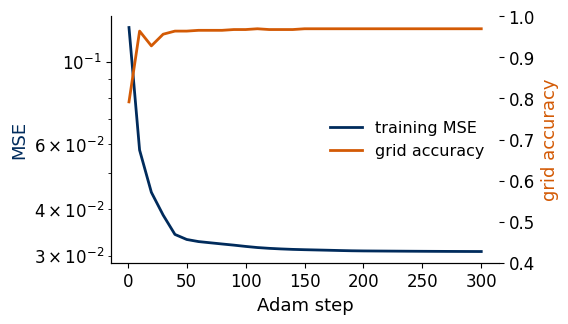

In [6]:
rng = np.random.default_rng(7)
PTS = np.column_stack([rng.uniform(0.05, 1.6, 40), rng.uniform(-1.6, 1.6, 40)])
X_TR = jnp.asarray(np.array([ground_state(T8, a, b) for a, b in PTS]))
Y_TR = np.array([float(v @ (S12 @ v) > 0.5) for v in (ground_state(T12, a, b) for a, b in PTS)])
X_TE, Y_TE = jnp.asarray(G8), LABELS.reshape(-1)

def mse(theta, states, labels):                               # equation (6)
    return 0.5 * jnp.mean((labels - qcnn_batch(theta, states)) ** 2)
mse_and_grad = jax.jit(jax.value_and_grad(mse))
accuracy = lambda th, Xs, ys: float(np.mean((np.asarray(qcnn_batch(th, Xs)) > 0.5) == (ys > 0.5)))

def train(theta, steps=300, lr=0.05):
    # Adam with exact gradients
    m, v, hist = jnp.zeros_like(theta), jnp.zeros_like(theta), []
    for t in range(1, steps + 1):
        L, g = mse_and_grad(theta, X_TR, Y_TR)
        m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g ** 2
        theta = theta - lr * (m / (1 - 0.9 ** t)) / (jnp.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
        if t == 1 or t % 10 == 0:
            hist.append((t, float(L), accuracy(theta, X_TE, Y_TE)))
    return theta, float(mse(theta, X_TR, Y_TR)), np.array(hist)

t0 = time.perf_counter()
runs = sorted((train(0.3 * jax.random.normal(jax.random.PRNGKey(s), (N_PAR,))) + (s,) for s in range(4)), key=lambda r: r[1])
THETA, LOSS, HIST, SEED = runs[0]
RESULTS["train_seconds"] = time.perf_counter() - t0
RESULTS["final_mse"] = LOSS; RESULTS["train_accuracy"] = accuracy(THETA, X_TR, Y_TR)
RESULTS["grid_accuracy_all_starts"] = [r[2][-1, 2] for r in runs]
print(f"{int(Y_TR.sum())} of 40 training states labelled SPT; training took {RESULTS['train_seconds']:.0f} s")
print(f"best start {SEED}: MSE = {LOSS:.4f}, training accuracy = {RESULTS['train_accuracy']:.3f}")
print("grid accuracy of the four starts:", np.round(RESULTS["grid_accuracy_all_starts"], 3))

fig, ax = plt.subplots(figsize=(5.0, 3.2))
ax.semilogy(HIST[:, 0], HIST[:, 1], color=NAVY, lw=2, label="training MSE")
ax.set_xlabel("Adam step"); ax.set_ylabel("MSE", color=NAVY)
ax2 = ax.twinx(); ax2.spines["top"].set_visible(False)
ax2.plot(HIST[:, 0], HIST[:, 2], color=ORANGE, lw=2, label="grid accuracy")
ax2.set_ylabel("grid accuracy", color=ORANGE); ax2.set_ylim(0.4, 1.0)
h_a, l_a = ax.get_legend_handles_labels(); h_b, l_b = ax2.get_legend_handles_labels()
ax.legend(h_a + h_b, l_a + l_b, loc="center right", frameon=False)
save(fig, "fig_lab070c_training"); plt.show()

The loss falls within the first fifty steps and then levels off, and the grid accuracy follows it closely and saturates near 0.97. All four starts reach similar accuracies, so the result does not depend on a lucky initialisation. The loss stays above zero because the output $p$ does not reach the values 0 and 1. The classification only needs $p$ on the correct side of $1/2$.

## 7. The predicted phase diagram

We apply the trained QCNN to all 528 grid states and compare the class $p>1/2$ with the reference labels of Section 4. As a baseline without any learning we also classify the same 8-qubit states by the rule $S_8>1/2$, which uses the knowledge that the string operator (3) is the right observable.

QCNN accuracy on the grid: 0.970  |  rule S_8 > 1/2: 0.962


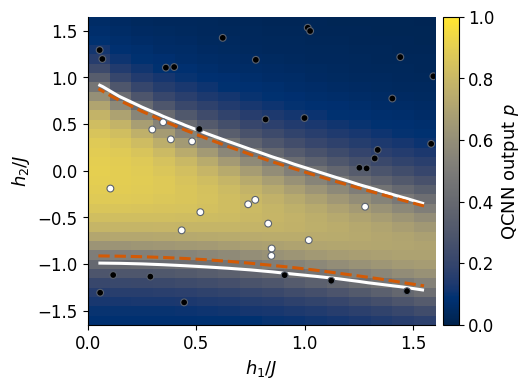

h1 = 0.5, value 1/2 crossed at h2 = {'S12': [-1.023, 0.442], 'S8': [-1.061, 0.497], 'QCNN': [-0.947, 0.388]} | DMRG [1]: 0.423


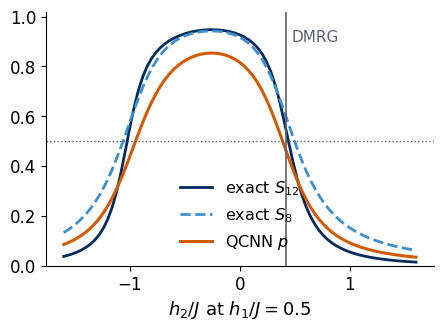

classroom route (Sections 1 to 7): 28 s


In [7]:
P_GRID = np.asarray(qcnn_batch(THETA, X_TE)).reshape(LABELS.shape)
ACC = float(np.mean((P_GRID > 0.5) == (LABELS > 0.5))); ACC_S8 = float(np.mean((sop8 > 0.5) == (LABELS > 0.5)))
RESULTS["grid_accuracy"] = ACC; RESULTS["grid_accuracy_rule_S8"] = ACC_S8
print(f"QCNN accuracy on the grid: {ACC:.3f}  |  rule S_8 > 1/2: {ACC_S8:.3f}")

fig, ax = plt.subplots(figsize=(5.4, 4.0))
im = ax.imshow(P_GRID, origin="lower", extent=EXT, aspect="auto", cmap="cividis", vmin=0, vmax=1)
ax.contour(H1_GRID, H2_GRID, sop12, levels=[0.5], colors="white", linewidths=2.2)
ax.contour(H1_GRID, H2_GRID, P_GRID, levels=[0.5], colors=ORANGE, linewidths=2.2, linestyles="--")
ax.scatter(PTS[:, 0], PTS[:, 1], s=24, c=["white" if y else "black" for y in Y_TR], edgecolors=GRAY, linewidths=0.8, zorder=3)
ax.set_xlabel(r"$h_1/J$"); ax.set_ylabel(r"$h_2/J$"); fig.colorbar(im, ax=ax, pad=0.02, label=r"QCNN output $p$")
save(fig, "fig_lab070c_phase_map"); plt.show()

h2_line = np.linspace(-1.6, 1.6, 81)
line8 = np.array([ground_state(T8, 0.5, b) for b in h2_line])
p_line = np.asarray(qcnn_batch(THETA, jnp.asarray(line8)))
s8_line = np.array([v @ (S8 @ v) for v in line8])
s12_line = np.array([(lambda v: v @ (S12 @ v))(ground_state(T12, 0.5, b)) for b in h2_line])
def crossings(y, x=h2_line):
    return [float(x[i] + (0.5 - y[i]) / (y[i + 1] - y[i]) * (x[i + 1] - x[i])) for i in range(len(y) - 1) if (y[i] - 0.5) * (y[i + 1] - 0.5) < 0]
RESULTS["line_h1_0.5"] = {"S12": crossings(s12_line), "S8": crossings(s8_line), "QCNN": crossings(p_line)}
print("h1 = 0.5, value 1/2 crossed at h2 =", {k: np.round(v, 3).tolist() for k, v in RESULTS["line_h1_0.5"].items()}, "| DMRG [1]: 0.423")

fig, ax = plt.subplots(figsize=(5.0, 3.3))
ax.plot(h2_line, s12_line, color=NAVY, lw=2, label=r"exact $S_{12}$")
ax.plot(h2_line, s8_line, color=BLUE, lw=2, ls="--", label=r"exact $S_8$")
ax.plot(h2_line, p_line, color=ORANGE, lw=2.2, label=r"QCNN $p$")
ax.axhline(0.5, color=GRAY, lw=1, ls=":"); ax.axvline(0.423, color=GRAY, lw=1.2)
ax.text(0.47, 0.9, "DMRG", color=GRAY, fontsize=11)
ax.set_xlabel(r"$h_2/J$ at $h_1/J=0.5$"); ax.set_ylim(0, 1.02); ax.legend(loc="lower center", frameon=False)
save(fig, "fig_lab070c_line"); plt.show()
RESULTS["classroom_seconds"] = time.perf_counter() - started
print(f"classroom route (Sections 1 to 7): {RESULTS['classroom_seconds']:.0f} s")

In the map the colour is the QCNN output $p$, the white line is the reference boundary $S_{12}=1/2$ and the dashed orange line is the learned boundary $p=1/2$. The dots are the training states, white for SPT and black otherwise. The learned boundary follows the reference along both edges of the SPT band, including the lower right part, where only a few training points lie. The misclassified grid points sit next to the boundary, where the 8-qubit states change gradually and even the exact string order of the 8-qubit chain disagrees with the 12-site reference.

The cut at $h_1=0.5$ shows the same comparison as curves. The QCNN output rises and falls where the string order does, and its upper crossing of $1/2$ lies slightly below the DMRG value, closer to it than the crossing of the 8-qubit string order, which lies above. The QCNN therefore classifies these 8-qubit states as accurately as the string order parameter evaluated on the same states, although it was never told which observable to measure. It learned a suitable measurement from 40 labelled examples with 57 angles.

## 8. Why the QCNN trains, and what Ref. [1] showed

The QCNN has depth $O(\log N)$, because every unit halves the register, and its output is a single-qubit measurement. Pesah and co-workers proved that for this architecture the variance of the gradient decreases at most polynomially with $N$ [4]. A QCNN therefore has no barren plateau, unlike deep hardware-efficient circuits, whose gradients vanish exponentially. Each angle influences the measured qubit only through a short chain of layers, and the shared parameters keep their number at $O(\log N)$, which also limits overfitting to a small training set.

Cong, Choi and Lukin [1] constructed an exact QCNN for this phase and simulated chains of up to 135 spins with matrix product states. Near the transition their QCNN needed far fewer copies of the input state to decide the phase with 95% confidence than a measurement of string order parameters, and the advantage grew with the number of convolution-pooling units. A QCNN trained on 15 spins with labels only from the line $h_2=0$ reproduced the full two-dimensional phase diagram. The authors also interpreted the circuit physically. Run backwards, a QCNN has the structure of the multiscale entanglement renormalisation ansatz (MERA), a tensor network for many-body states, and its pooling layers act like the syndrome measurements and corrections of quantum error correction, which remove local perturbations of the cluster state at every scale. The same network trained as a decoder gave error-correcting codes adapted to a given noise model.

The classroom route ends here.

## 9. Optional. A second determination of the boundary

A phase transition shows up as a sudden change of the ground state. The fidelity susceptibility measures this change, $\chi_F=\big(1-\lvert\langle\psi(h_2)\vert\psi(h_2+\delta)\rangle\rvert\big)/(N\delta^2)$ for a small step $\delta$, and peaks at the transition without any reference to an order parameter. We compute it for the 12-site ring along $h_2$ at eight values of $h_1$ and compare the positions of its maxima with the line $S_{12}=1/2$.

17 s; maxima (h1, h2): (0.05, -0.98); (0.05, 0.92); (0.25, -0.99); (0.25, 0.66); (0.45, -1.01); (0.45, 0.46); (0.65, -1.05); (0.65, 0.29); (0.85, -1.10); (0.85, 0.14); (1.05, -1.16); (1.05, 0.00); (1.25, -1.23); (1.25, -0.12); (1.45, -1.31); (1.45, -0.24)


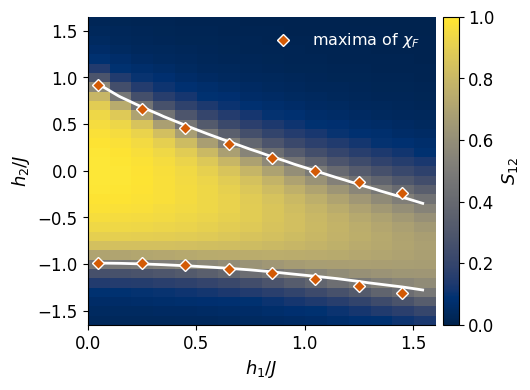

In [8]:
t0 = time.perf_counter()
d, hs, peaks = 1e-3, np.round(np.arange(-1.6, 1.6001, 0.05), 3), []
for a in H1_GRID[::2]:
    chi = np.array([(1 - abs(ground_state(T12, a, b) @ ground_state(T12, a, b + d))) / d ** 2 / 12 for b in hs])
    for i in range(1, len(hs) - 1):
        if chi[i] > chi[i - 1] and chi[i] > chi[i + 1]:
            den = chi[i - 1] - 2 * chi[i] + chi[i + 1]                  # parabola through three points
            peaks.append((a, hs[i] + 0.5 * 0.05 * (chi[i - 1] - chi[i + 1]) / den))
peaks = np.array(peaks)
RESULTS["chi_peaks"] = peaks.tolist()
print(f"{time.perf_counter() - t0:.0f} s; maxima (h1, h2):", "; ".join(f"({a:.2f}, {b:.2f})" for a, b in peaks))

fig, ax = plt.subplots(figsize=(5.4, 4.0))
im = ax.imshow(sop12, origin="lower", extent=EXT, aspect="auto", cmap="cividis", vmin=0, vmax=1)
ax.contour(H1_GRID, H2_GRID, sop12, levels=[0.5], colors="white", linewidths=2)
ax.plot(peaks[:, 0], peaks[:, 1], "D", color=ORANGE, mec="white", ms=6, label=r"maxima of $\chi_F$")
ax.set_xlabel(r"$h_1/J$"); ax.set_ylabel(r"$h_2/J$"); ax.legend(loc="upper right", frameon=False, labelcolor="white")
fig.colorbar(im, ax=ax, pad=0.02, label=r"$S_{12}$")
save(fig, "fig_lab070c_susceptibility"); plt.show()

The maxima of the fidelity susceptibility lie on the line $S_{12}=1/2$ to within about 0.06 in $h_2$ along both boundaries. Two unrelated criteria, a threshold of the string order and the sharpest change of the ground state, thus give the same phase diagram for the 12-site ring, which supports its use as the reference for the labels.

In [9]:
RESULTS["n_parameters"] = N_PAR
RESULTS["total_seconds"] = time.perf_counter() - started
(RES / "lab070c_results.json").write_text(json.dumps(RESULTS, indent=2, default=float))
print(f"whole notebook: {RESULTS['total_seconds']:.0f} s")

whole notebook: 46 s


## 10. Exercises

1. Train only on 40 points of the line $h_2=0$, with labels $h_1<J$ for SPT, as Ref. [1] did, and draw the predicted map over the whole grid. Find which part of the phase diagram the network gets wrong and explain why with the training states it has seen.
2. Shots. On a device $p$ is estimated as the fraction $\tilde p$ of $S$ shots that return 1. Sample $\tilde p$ with $S=100$ along the cut $h_1=0.5$ and count how many grid points change their class. Repeat with $S=1000$.
3. Replace the mean squared error (6) by the cross-entropy $-\frac1M\sum_\alpha[y_\alpha\ln p_\alpha+(1-y_\alpha)\ln(1-p_\alpha)]$ and compare the outputs $p$ deep inside the phases.
4. Count the parameters of a QCNN for $N=16$ and $N=64$ from equation (1), and compare with a hardware-efficient circuit of depth $L=N$ that has $2N(L+1)$ angles.
5. Give the convolution a separate unitary for the even and for the odd pairs. Count the parameters and check whether the grid accuracy changes.

## 11. Summary

A quantum convolutional neural network classifies a quantum state on the device that prepared it. Convolution layers apply one shared two-qubit unitary to all neighbouring pairs, pooling layers measure half of the qubits and rotate their partners according to the outcomes, and a final unitary with one measured qubit returns the class probability. Since every layer halves the register, the circuit has depth and parameter count of order $\log N$. We trained such a network with 57 angles on 40 ground states of the 8-qubit cluster-Ising ring, labelled by the exact string order parameter of a 12-site ring. The trained network recognised the symmetry-protected topological phase on 97% of a grid of 528 points, as accurately as the string order parameter evaluated on the same states, and its errors lie next to the phase boundary. The reference boundary agrees with the maxima of the fidelity susceptibility and, at $h_1=0.5$, with the DMRG value of Ref. [1]. All numbers are exact state-vector results, whereas a device would estimate $p$ from repeated measurements of one qubit.

## References

[1] I. Cong, S. Choi, and M. D. Lukin, Quantum convolutional neural networks, Nat. Phys. **15**, 1273 (2019), [doi:10.1038/s41567-019-0648-8](https://doi.org/10.1038/s41567-019-0648-8).

[2] F. Pollmann and A. M. Turner, Detection of symmetry-protected topological phases in one dimension, Phys. Rev. B **86**, 125441 (2012), [doi:10.1103/PhysRevB.86.125441](https://doi.org/10.1103/PhysRevB.86.125441).

[3] D. P. Kingma and J. Ba, Adam: a method for stochastic optimization, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980) (2014).

[4] A. Pesah, M. Cerezo, S. Wang, T. Volkoff, A. T. Sornborger, and P. J. Coles, Absence of barren plateaus in quantum convolutional neural networks, Phys. Rev. X **11**, 041011 (2021), [doi:10.1103/PhysRevX.11.041011](https://doi.org/10.1103/PhysRevX.11.041011).